# Ödev 24 - CNN ile CIFAR-10 Görüntü Sınıflandırma

## Ödev hakkında

**Problem:** CIFAR-10 veri setindeki 32x32 renkli görüntüleri 10 sınıfa (uçak, otomobil, kuş, kedi, geyik, köpek, kurbağa, at, gemi, kamyon) ayıran bir CNN kurmak.

**Konu:** Görüntü verisini kontrol etme, normalizasyon, Conv2D / MaxPooling2D ile CNN, veri çoğaltma (data augmentation), EarlyStopping, karışıklık matrisi, modeli kaydetme ve Streamlit uygulaması.

**Metrik:** Test accuracy (hedef %80) ve sınıf bazında F1.

**Veri:** `tensorflow.keras.datasets.cifar10`: 50.000 eğitim ve 10.000 test görüntüsü.

## Kütüphaneleri yüklüyor ve veriyi okuyoruz.

Kütüphaneleri yükleyip CIFAR-10'u Keras'tan okuyoruz.

In [1]:
import numpy as np # matematik paketi
import pandas as pd # tablo işlemleri
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # sns havalı grafik oluşturma paketi
import tensorflow as tf # derin öğrenme
from tensorflow.keras.datasets import cifar10 # veri seti

(x_train, y_train), (x_test, y_test) = cifar10.load_data() # eğitim ve test verisi
class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck'] # sınıf adları
print('Eğitim:', x_train.shape, y_train.shape) # boyutlar
print('Test:', x_test.shape, y_test.shape) # boyutlar

Eğitim: (50000, 32, 32, 3) (50000, 1)
Test: (10000, 32, 32, 3) (10000, 1)


**Sonuç:** Keras'tan 50.000 eğitim ve 10.000 test görüntüsü geldi; her görüntü 32x32 piksel ve 3 renk kanallı.

## Veri kontrolü

Sınıf dağılımına, piksel aralığına ve etiket biçimine bakıyoruz.

In [2]:
y_train=y_train.ravel() # (50000,1) -> (50000,)
y_test=y_test.ravel() # (10000,1) -> (10000,)
dagilim=pd.DataFrame({'Eğitim':pd.Series(y_train).value_counts().sort_index(), 'Test':pd.Series(y_test).value_counts().sort_index()}) # sınıf sayıları
dagilim.index=class_names # sınıf adları
print('Piksel aralığı:', x_train.min(), '-', x_train.max(), '| tip:', x_train.dtype) # piksel değerleri
dagilim.T # tablo

Piksel aralığı: 0 - 255 | tip: uint8


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
Eğitim,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
Test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


**Sonuç:** Her sınıfta eğitimde 5.000, testte 1.000 görüntü var; veri tamamen dengeli. Pikseller 0-255 aralığında ve tam sayı (uint8). Etiketler (50000, 1) biçiminde geldiği için tek boyuta indirildi.

Aynı görüntünün eğitimde birden fazla olup olmadığını ve test görüntülerinin eğitimde birebir bulunup bulunmadığını (sızıntı) kontrol ediyoruz.

In [3]:
egitim_kod=[hash(img.tobytes()) for img in x_train] # her eğitim görüntüsünün özeti
test_kod=[hash(img.tobytes()) for img in x_test] # her test görüntüsünün özeti
print('Eğitim içinde tekrar eden görüntü:', len(egitim_kod)-len(set(egitim_kod))) # tekrarlar
print('Testte olup eğitimde birebir bulunan görüntü:', len(set(test_kod) & set(egitim_kod))) # sızıntı

Eğitim içinde tekrar eden görüntü: 0
Testte olup eğitimde birebir bulunan görüntü: 0


**Sonuç:** Eğitimde birebir tekrar eden görüntü yok ve test görüntülerinin hiçbiri eğitimde birebir bulunmuyor; sızıntı yok.

Her sınıftan birer örnek görüntüyü çiziyoruz.

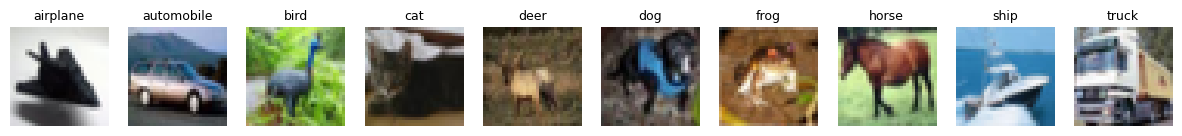

In [4]:
plt.figure(figsize=(15,3)) # grafik boyutu
for i in range(10): # her sınıf
    plt.subplot(1,10,i+1) # alt grafik
    plt.imshow(x_train[np.where(y_train==i)[0][0]]) # sınıfın ilk görüntüsü
    plt.title(class_names[i], fontsize=9) # sınıf adı
    plt.axis('off') # eksenleri gizle
plt.show() # göster

Piksel değerlerini 255'e bölerek 0-1 aralığına getiriyoruz.

In [5]:
x_train=x_train.astype('float32')/255.0 # eğitim normalizasyonu
x_test=x_test.astype('float32')/255.0 # test normalizasyonu
print(x_train.min(), x_train.max()) # kontrol

0.0 1.0


İki modelin sonuçlarını aynı tabloyla göstermek için bir değerlendirme fonksiyonu yazıyoruz.

In [6]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report # başarı ölçüleri

def degerlendir(model, isim): # eğitim ve test sonuçları
    tablo=pd.DataFrame(columns=['Accuracy','F1 (macro)'], index=[isim+' - Eğitim', isim+' - Test']) # tablo
    for veri, xx, yy in [('Eğitim', x_train, y_train), ('Test', x_test, y_test)]: # iki veri
        tahmin=model.predict(xx, verbose=0).argmax(axis=1) # en olası sınıf
        tablo.loc[isim+' - '+veri]=[accuracy_score(yy,tahmin), f1_score(yy,tahmin,average='macro')] # sonuçlar
    return tablo # tablo

## Model 1: Basit CNN

Karşılaştırma için 12 filtreli tek evrişim ve tek havuzlama katmanından oluşan basit bir CNN kuruyoruz.

In [7]:
from tensorflow.keras.models import Sequential # sıralı model
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D # derslerdeki katmanlar
from tensorflow.keras.callbacks import EarlyStopping # erken durdurma
basit=Sequential() # boş model
basit.add(Input(shape=(32,32,3))) # giriş: 32x32 renkli görüntü
basit.add(Conv2D(12, kernel_size=(3,3), activation='relu')) # tek evrişim
basit.add(MaxPooling2D(pool_size=(2,2))) # havuzlama
basit.add(Flatten()) # satıra aç
basit.add(Dense(10, activation='softmax')) # çıkış: 10 sınıfın olasılığı
basit.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) # derle
history_basit=basit.fit(x_train, y_train, validation_split=0.10, epochs=10, batch_size=64, verbose=0) # 10 epoch
sonuc_basit=degerlendir(basit, 'Basit CNN') # sonuçlar
sonuc_basit # tablo

,Accuracy,F1 (macro)
Basit CNN - Eğitim,0.63994,0.637722
Basit CNN - Test,0.5926,0.589113


**Sonuç:** Tek katmanlı basit CNN testte yaklaşık %59,3 doğruluk verdi (eğitimde %64,0); %80 hedefinin çok altında. Bu model kenar gibi basit özellikleri öğrenebiliyor ama hayvan ve araç ayrımı için gereken karmaşık şekilleri yakalayamıyor.

## Model 2: Daha derin CNN ve veri çoğaltma

Üç evrişim bloğu olan bir CNN kuruyoruz. Ezberlemeyi azaltmak için başına, sadece eğitimde çalışan yatay çevirme ve kaydırma katmanları ekliyoruz.

In [8]:
from tensorflow.keras.layers import RandomFlip, RandomTranslation # veri çoğaltma katmanları (sadece eğitimde çalışır)
cnn=Sequential() # boş model
cnn.add(Input(shape=(32,32,3))) # giriş
cnn.add(RandomFlip('horizontal')) # rastgele yatay çevirme
cnn.add(RandomTranslation(0.1, 0.1)) # rastgele %10 kaydırma
cnn.add(Conv2D(32, kernel_size=(3,3), activation='relu', padding='same')) # 1. evrişim
cnn.add(Conv2D(32, kernel_size=(3,3), activation='relu', padding='same')) # 2. evrişim
cnn.add(MaxPooling2D(pool_size=(2,2))) # 32 -> 16
cnn.add(Conv2D(64, kernel_size=(3,3), activation='relu', padding='same')) # 3. evrişim
cnn.add(Conv2D(64, kernel_size=(3,3), activation='relu', padding='same')) # 4. evrişim
cnn.add(MaxPooling2D(pool_size=(2,2))) # 16 -> 8
cnn.add(Conv2D(128, kernel_size=(3,3), activation='relu', padding='same')) # 5. evrişim
cnn.add(Conv2D(128, kernel_size=(3,3), activation='relu', padding='same')) # 6. evrişim
cnn.add(MaxPooling2D(pool_size=(2,2))) # 8 -> 4
cnn.add(Flatten()) # satıra aç
cnn.add(Dense(128, activation='relu')) # gizli katman
cnn.add(Dense(10, activation='softmax')) # çıkış: 10 sınıf
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) # derle
cnn.summary() # model özeti

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 550,570 (2.10 MB)

 Trainable params: 550,570 (2.10 MB)

 Non-trainable params: 0 (0.00 B)

Modeli en fazla 40 epoch eğitiyoruz; doğrulama kaybı 5 epoch iyileşmezse en iyi ağırlıklara dönüp duruyoruz.

Epoch 1/40
704/704 - 67s - 95ms/step - accuracy: 0.3989 - loss: 1.6293 - val_accuracy: 0.5514 - val_loss: 1.2312
Epoch 2/40
704/704 - 80s - 114ms/step - accuracy: 0.5768 - loss: 1.1797 - val_accuracy: 0.6354 - val_loss: 1.0185
Epoch 3/40
704/704 - 80s - 114ms/step - accuracy: 0.6463 - loss: 0.9984 - val_accuracy: 0.7112 - val_loss: 0.8275
Epoch 4/40
704/704 - 82s - 117ms/step - accuracy: 0.6880 - loss: 0.8835 - val_accuracy: 0.6972 - val_loss: 0.8904
Epoch 5/40
704/704 - 83s - 118ms/step - accuracy: 0.7216 - loss: 0.7925 - val_accuracy: 0.7362 - val_loss: 0.7629
Epoch 6/40
704/704 - 82s - 116ms/step - accuracy: 0.7422 - loss: 0.7314 - val_accuracy: 0.7466 - val_loss: 0.7624
Epoch 7/40
704/704 - 81s - 116ms/step - accuracy: 0.7618 - loss: 0.6819 - val_accuracy: 0.7762 - val_loss: 0.6640
Epoch 8/40
704/704 - 80s - 114ms/step - accuracy: 0.7750 - loss: 0.6403 - val_accuracy: 0.7930 - val_loss: 0.6231
Epoch 9/40
704/704 - 84s - 120ms/step - accuracy: 0.7863 - loss: 0.6093 - val_accuracy: 0

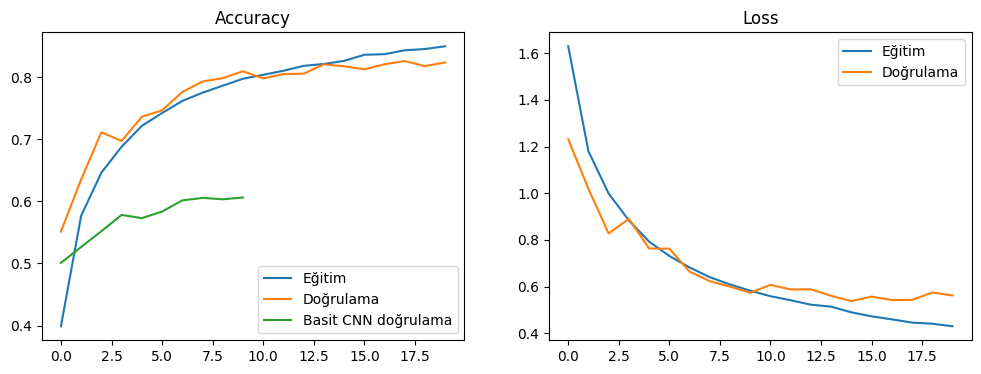

In [9]:
erken=EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True) # erken durdurma
history=cnn.fit(x_train, y_train, validation_split=0.10, epochs=40, batch_size=64, callbacks=[erken], verbose=2) # eğit, her epoch ekrana yazılır (test verisi kullanılmıyor)
print('Eğitilen epoch:', len(history.history['loss'])) # kaç epoch
fig=plt.figure(figsize=(12,4)) # grafik
ax=fig.add_subplot(1,2,1) # 1. grafik
ax.plot(history.history['accuracy'], label='Eğitim') # eğitim doğruluğu
ax.plot(history.history['val_accuracy'], label='Doğrulama') # doğrulama doğruluğu
ax.plot(history_basit.history['val_accuracy'], label='Basit CNN doğrulama') # karşılaştırma
ax.set_title('Accuracy') # başlık
ax.legend() # açıklama
ax=fig.add_subplot(1,2,2) # 2. grafik
ax.plot(history.history['loss'], label='Eğitim') # eğitim kaybı
ax.plot(history.history['val_loss'], label='Doğrulama') # doğrulama kaybı
ax.set_title('Loss') # başlık
ax.legend() # açıklama
plt.show() # göster

**Sonuç:** Doğrulama kaybı 15. epoch'ta en düşük değere (0,538) indi; sonraki 5 epoch'ta iyileşmediği için EarlyStopping eğitimi 20. epoch'ta durdurup 15. epoch'un ağırlıklarına döndü. Eğitim ve doğrulama eğrileri birbirine yakın; veri çoğaltma sayesinde belirgin bir ezberleme yok. Derin CNN'in doğrulama doğruluğu (yaklaşık %82) basit modelin (yaklaşık %60) çok üstünde.

Derin CNN'in eğitim ve test sonuçlarını ve sınıf bazında raporu çıkarıyoruz.

In [10]:
sonuc_cnn=degerlendir(cnn, 'Derin CNN') # sonuçlar
tahmin=cnn.predict(x_test, verbose=0).argmax(axis=1) # test tahminleri
print(classification_report(y_test, tahmin)) # 0=airplane ... 9=truck
sonuc_cnn # tablo

              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1000
           1       0.92      0.90      0.91      1000
           2       0.71      0.73      0.72      1000
           3       0.72      0.56      0.63      1000
           4       0.79      0.78      0.79      1000
           5       0.76      0.70      0.73      1000
           6       0.69      0.94      0.80      1000
           7       0.87      0.84      0.85      1000
           8       0.91      0.89      0.90      1000
           9       0.87      0.90      0.88      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.81     10000
weighted avg       0.81      0.81      0.81     10000



,Accuracy,F1 (macro)
Derin CNN - Eğitim,0.85382,0.852614
Derin CNN - Test,0.8071,0.805183


**Sonuç:** Derin CNN testte **yaklaşık %80,7 accuracy** ve 0,805 macro F1 verdi (eğitim yaklaşık %85,4). En iyi tanınan sınıflar otomobil (F1 0,91), gemi (0,90) ve kamyon (0,88); en zor sınıf kedi (0,63), ardından kuş (0,72) ve köpek (0,73). Kurbağa sınıfının recall değeri yüksek (0,94) ama precision değeri düşük (0,69): model başka sınıfları da sık sık kurbağa olarak tahmin ediyor.

Test karışıklık matrisini çiziyoruz (satır gerçek, sütun tahmin).

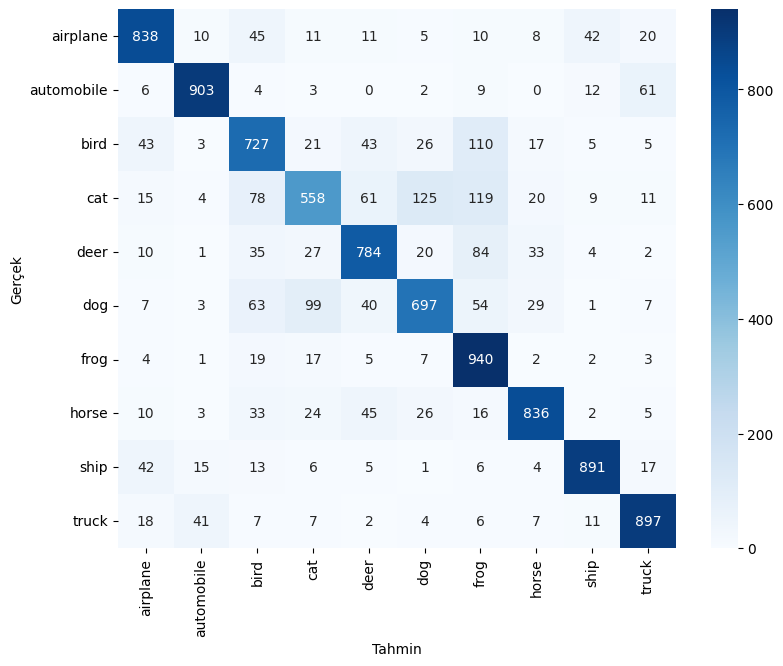

In [11]:
plt.figure(figsize=(9,7)) # grafik boyutu
sns.heatmap(confusion_matrix(y_test, tahmin), annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names) # karışıklık matrisi
plt.xlabel('Tahmin'); plt.ylabel('Gerçek') # eksenler
plt.show() # göster

**Sonuç:** En sık karışıklık kedilerde: 125 kedi köpek, 119 kedi kurbağa olarak tahmin edildi; 99 köpek de kedi olarak tahmin edildi. Kuşlar (110) ve geyikler (84) sık sık kurbağa ile, otomobiller (61) kamyon ile karışıyor. 32x32'lik düşük çözünürlükte bu sınıflar benzer renk ve şekillere sahip.

Yanlış tahmin edilen birkaç test görüntüsüne bakıyoruz.

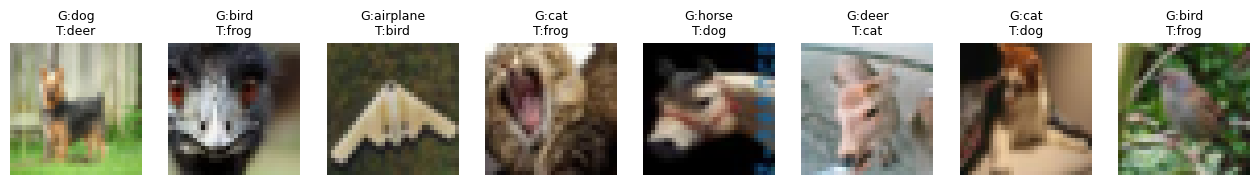

In [12]:
yanlis=np.where(tahmin!=y_test)[0][:8] # ilk 8 hata
plt.figure(figsize=(16,3)) # grafik boyutu
for i, j in enumerate(yanlis): # her hata
    plt.subplot(1,8,i+1) # alt grafik
    plt.imshow(x_test[j]) # görüntü
    plt.title('G:'+class_names[y_test[j]]+'\nT:'+class_names[tahmin[j]], fontsize=9) # gerçek ve tahmin
    plt.axis('off') # eksenleri gizle
plt.show() # göster

**Sonuç:** Hatalı tahminlerde hayvanlar çoğunlukla yakın plan, alışılmadık açıdan ya da karmaşık bir arka plan önünde çekilmiş (örneğin yeşil yapraklar arasındaki kuş kurbağa olarak tahmin edildi); bazılarını insan gözüyle de ayırt etmek zor.

İki modeli karşılaştırıp derin CNN'i kaydediyoruz.

In [13]:
karsilastirma=pd.DataFrame(columns=['Accuracy','F1 (macro)']) # tablo
karsilastirma.loc['Basit CNN - Test']=sonuc_basit.loc['Basit CNN - Test'] # basit model
karsilastirma.loc['Derin CNN - Test']=sonuc_cnn.loc['Derin CNN - Test'] # derin model
cnn.save('cifar10_cnn_rwz.keras') # modeli kaydet
print('Kaydedildi: cifar10_cnn_rwz.keras') # bilgi
karsilastirma.astype(float).round(3) # tablo

Kaydedildi: cifar10_cnn_rwz.keras


,Accuracy,F1 (macro)
Basit CNN - Test,0.593,0.589
Derin CNN - Test,0.807,0.805


**Sonuç:** Derin CNN basit modele göre test doğruluğunu yaklaşık 21 puan artırdı (%59,3 → %80,7). Model `cifar10_cnn_rwz.keras` olarak kaydedildi.

## Sonuçların Değerlendirilmesi

| Model | Test Accuracy | Test F1 (macro) |
|---|---|---|
| Basit CNN | yaklaşık 0,593 | yaklaşık 0,589 |
| Derin CNN + veri çoğaltma | yaklaşık 0,807 | yaklaşık 0,805 |

**Hedef (%80) aşıldı:** derin CNN testte yaklaşık %80,7 doğruluk verdi.

- `app_rwz.py` kaydedilen modeli yükleyip yüklenen fotoğrafı sınıflandırıyor.
- Veri kontrolünde sınıfların dengeli olduğu, tekrar eden görüntü ve eğitim-test sızıntısı olmadığı görüldü.
- En zor sınıflar kedi, kuş ve köpek; bu sınıflar en çok birbirleriyle ve kurbağa sınıfıyla karışıyor. Sinir ağı sonuçları her çalıştırmada biraz değişebileceği için değerler yaklaşık olarak verildi.

**Kaydedilen dosyalar:** `cifar10_cnn_rwz.keras`, `app_rwz.py`